# EU Regional Convergence Project
## Complete compiled analysis of GDP and employment convergence across EU NUTS 2 regions, 2016–2024

This notebook brings together the strongest analysis and visuals from the four group contributions:

1. **RQ1A:** Is the GDP spread between regions narrowing year by year?
2. **RQ1B:** Are employment gaps between regions narrowing?
3. **RQ2:** Do poorer regions grow faster than richer regions?
4. **RQ3:** Which regions behave alike based on GDP, employment, and unemployment?
5. **RQ4:** Where do sigma and beta convergence agree or disagree?

The notebook is designed to run from either the project root or the `notebooks` folder. It uses the existing `src`, `data`, and `outputs` structure and does not duplicate the full code of every group member.

## 0. Setup and project paths

The next cell finds the project root, creates common display helpers, and confirms the main folders. Run the notebook inside the `EU_Regional_Convergence_Project` repository.

In [1]:
from pathlib import Path
import sys
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.precision", 4)


def locate_project_root():
    cwd = Path.cwd().resolve()
    candidates = [cwd, *cwd.parents]
    for candidate in candidates:
        if (candidate / "data").exists() and (candidate / "src").exists():
            return candidate
    raise FileNotFoundError(
        "Project root not found. Open this notebook inside the EU_Regional_Convergence_Project repository."
    )

ROOT = locate_project_root()
DATA = ROOT / "data"
OUTPUTS = ROOT / "outputs"
SRC = ROOT / "src"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


def show_image(path, width=900):
    path = Path(path)
    if path.exists():
        display(Image(filename=str(path), width=width))
    else:
        print(f"Visual not found: {path}. Run the relevant analysis script first.")


def show_csv(path, columns=None, decimals=3, index_col=None):
    path = Path(path)
    if not path.exists():
        print(f"Table not found: {path}. Run the relevant analysis script first.")
        return None
    frame = pd.read_csv(path, index_col=index_col)
    if columns is not None:
        columns = [col for col in columns if col in frame.columns]
        frame = frame[columns]
    display(frame.round(decimals))
    return frame

print("Project root:", ROOT)
print("Data folder:", DATA)
print("Outputs folder:", OUTPUTS)

Project root: /Users/felix/EU_Regional_Convergence_Project
Data folder: /Users/felix/EU_Regional_Convergence_Project/data
Outputs folder: /Users/felix/EU_Regional_Convergence_Project/outputs


## 1. Run the group analysis pipelines

This cell runs the available source scripts so that the tables and figures are refreshed before the compiled results are displayed. A missing script is reported without stopping the whole notebook.

In [2]:
from runpy import run_path

pipeline_candidates = {
    "RQ1A GDP dispersion": [SRC / "rq1a_dispersion.py"],
    "RQ1B employment dispersion": [SRC / "rq1b_employment_dispersion.py", SRC / "rq1b_report.py"],
    "RQ2 beta convergence": [SRC / "12_rq2_beta_convergence.py", SRC / "rq2_beta_convergence.py"],
    "RQ4 sigma versus beta": [SRC / "11_rq4_sigma_vs_beta.py", SRC / "rq4_sigma_vs_beta.py"],
}

for label, candidates in pipeline_candidates.items():
    script = next((p for p in candidates if p.exists()), None)
    if script is None:
        print(f"SKIPPED: {label}. No matching source script was found.")
        continue
    print(f"RUNNING: {label} -> {script.name}")
    try:
        if script.name == "rq1a_dispersion.py":
            from src.rq1a_dispersion import main as rq1a_main
            rq1a_main(DATA / "eu_nuts2_master_panel.csv", OUTPUTS / "rq1a")
        else:
            run_path(str(script), run_name="__main__")
        print(f"COMPLETED: {label}")
    except Exception as exc:
        print(f"WARNING: {label} did not complete: {exc}")

RUNNING: RQ1A GDP dispersion -> rq1a_dispersion.py
SKIPPED: RQ1B employment dispersion. No matching source script was found.
RUNNING: RQ2 beta convergence -> 12_rq2_beta_convergence.py
RUNNING: RQ4 sigma versus beta -> 11_rq4_sigma_vs_beta.py
Regions: 244  years: 2016-2024
RQ4 SUMMARY: sigma vs beta convergence, EU NUTS 2, 2016-2024

BETA (full period)
  All regions:      beta = -0.0167 (t = -7.0), R2 = 0.24, half-life = 39 years
  Without outliers: beta = -0.0187, R2 = 0.28
  Within countries: beta = -0.0050 (t = -2.0)
  Between countries: beta = -0.0201 (t = -3.2)

SIGMA (% change 2016 -> 2024)
  sd_log                 -10.1%  (rose in 1 of 8 years)
  cv                     -4.6%  (rose in 3 of 8 years)
  p90_p10                -15.8%  (rose in 1 of 8 years)
  sd_log_excl_outliers   -11.7%  (rose in 1 of 8 years)
  cv_excl_outliers       -7.8%  (rose in 1 of 8 years)

WHERE THEY DISAGREE
  Years where beta < 0 but CV rose:          2019-2020, 2020-2021, 2021-2022
  Years where beta <

# Part A. Sigma convergence
Sigma convergence asks whether the spread in regional outcomes becomes smaller over time.

## 2. RQ1A: Is the GDP spread narrowing year by year?

The GDP analysis uses the coefficient of variation, standard deviation, percentile gaps, period comparisons, and sensitivity checks. The strongest visual is the indexed dispersion chart because it places the different measures on a common 2016 baseline.

In [ ]:
rq1a_out = OUTPUTS / "rq1a"
rq1a_annual = show_csv(
    rq1a_out / "annual_dispersion_enhanced.csv",
    ["year", "n_regions", "cv_pct", "sd", "p90_p10_gap", "cv_pct_change", "sd_change", "p90_p10_gap_change"],
    decimals=2,
)
show_image(rq1a_out / "figure_1_indexed_dispersion.png")

### RQ1A interpretation

The central question is answered by the direction of the dispersion measures. A sustained decline indicates sigma convergence. The full project results show that regional GDP dispersion declined overall from 2016 to 2024, although convergence was not identical in every year. The outlier and data-quality checks should be used to confirm that the result is not driven only by exceptional regions or provisional observations.

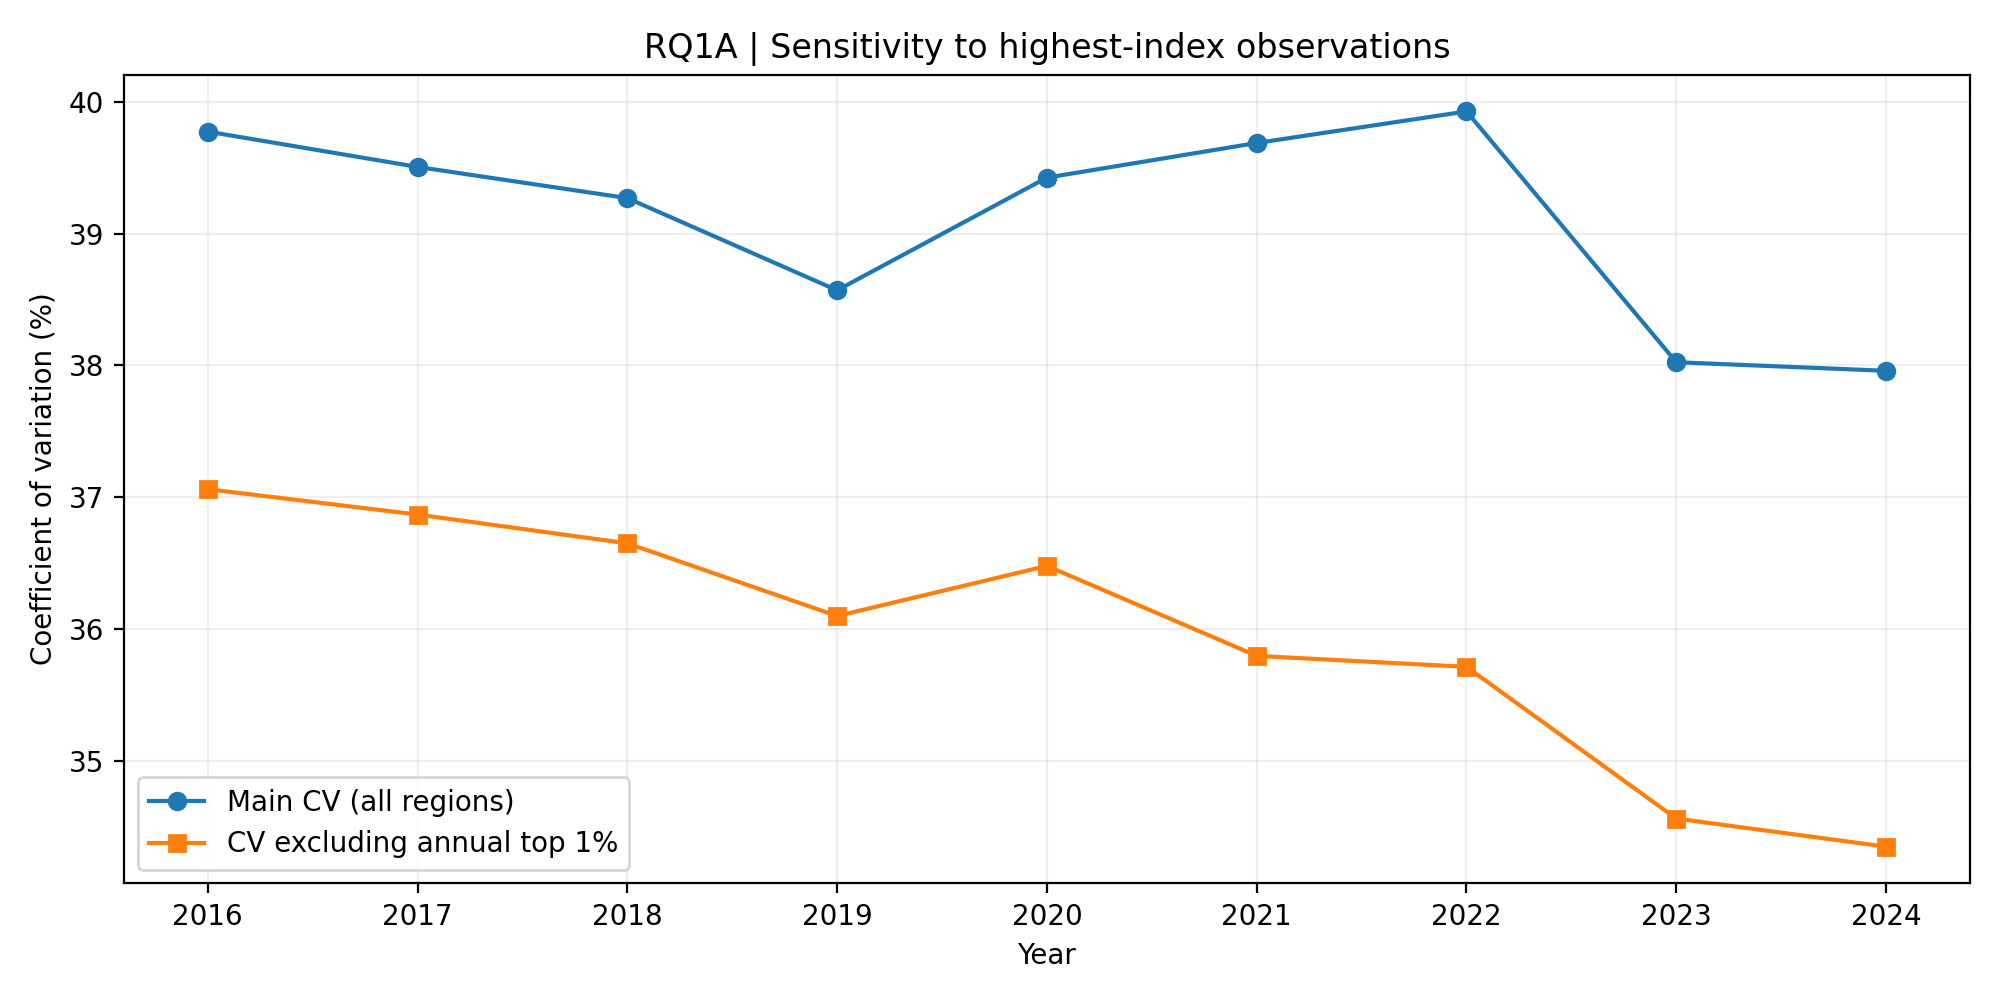

,year,n_regions_main,cv_pct_main,sd_main,p90_p10_gap_main,iqr,n_regions_trim_top_1pct,cv_pct_trim_top_1pct,sd_trim_top_1pct,p90_p10_gap_trim_top_1pct,cv_difference_pp
0,2016,244,39.77,37.56,88.7,48.25,241,37.06,34.37,86.0,-2.71
1,2017,244,39.51,37.25,90.1,47.50,241,36.87,34.14,86.0,-2.64
2,2018,244,39.27,36.98,90.7,47.00,241,36.65,33.89,87.0,-2.62
3,2019,244,38.57,36.23,85.7,46.25,241,36.10,33.33,83.0,-2.47
4,2020,244,39.43,37.15,85.7,45.25,241,36.48,33.72,82.0,-2.95
5,2021,244,39.69,37.35,83.0,44.50,241,35.79,32.97,81.0,-3.89
6,2022,244,39.93,37.67,84.0,44.00,241,35.71,32.95,78.0,-4.22
7,2023,244,38.02,35.81,79.4,41.25,241,34.56,31.91,76.0,-3.46
8,2024,244,37.96,35.69,75.7,39.25,241,34.35,31.65,74.0,-3.61


,year,n_regions_main,cv_pct_main,sd_main,p90_p10_gap_main,iqr,n_regions_trim_top_1pct,cv_pct_trim_top_1pct,sd_trim_top_1pct,p90_p10_gap_trim_top_1pct,cv_difference_pp
0,2016,244,39.77,37.56,88.7,48.25,241,37.06,34.37,86.0,-2.71
1,2017,244,39.51,37.25,90.1,47.50,241,36.87,34.14,86.0,-2.64
2,2018,244,39.27,36.98,90.7,47.00,241,36.65,33.89,87.0,-2.62
3,2019,244,38.57,36.23,85.7,46.25,241,36.10,33.33,83.0,-2.47
4,2020,244,39.43,37.15,85.7,45.25,241,36.48,33.72,82.0,-2.95
5,2021,244,39.69,37.35,83.0,44.50,241,35.79,32.97,81.0,-3.89
6,2022,244,39.93,37.67,84.0,44.00,241,35.71,32.95,78.0,-4.22
7,2023,244,38.02,35.81,79.4,41.25,241,34.56,31.91,76.0,-3.46
8,2024,244,37.96,35.69,75.7,39.25,241,34.35,31.65,74.0,-3.61


,year,n_regions_main,cv_pct_main,sd_main,p90_p10_gap_main,iqr,n_regions_trim_top_1pct,cv_pct_trim_top_1pct,sd_trim_top_1pct,p90_p10_gap_trim_top_1pct,cv_difference_pp
0,2016,244,39.7746,37.5593,88.7,48.25,241,37.0598,34.3672,86.0,-2.7148
1,2017,244,39.5064,37.2478,90.1,47.50,241,36.8671,34.1395,86.0,-2.6394
2,2018,244,39.2697,36.9779,90.7,47.00,241,36.6488,33.8948,87.0,-2.6209
3,2019,244,38.5696,36.2348,85.7,46.25,241,36.0969,33.3260,83.0,-2.4727
4,2020,244,39.4251,37.1501,85.7,45.25,241,36.4773,33.7241,82.0,-2.9478
5,2021,244,39.6881,37.3475,83.0,44.50,241,35.7943,32.9694,81.0,-3.8938
6,2022,244,39.9277,37.6712,84.0,44.00,241,35.7111,32.9535,78.0,-4.2166
7,2023,244,38.0237,35.8092,79.4,41.25,241,34.5591,31.9076,76.0,-3.4646
8,2024,244,37.9585,35.6857,75.7,39.25,241,34.3457,31.6508,74.0,-3.6128


In [4]:
rq1a_out = OUTPUTS / "rq1a"
show_image(rq1a_out / "figure_3_outlier_sensitivity.png")
show_csv(rq1a_out / "outlier_sensitivity.csv", decimals=2)
show_csv(rq1a_out / "outlier_sensitivity.csv", decimals=2)

## 3. RQ1B: Are employment gaps narrowing?

Employment convergence is evaluated with the standard deviation, coefficient of variation, and P90 minus P10 gap. The balanced panel is especially useful because it compares the same regions in every year.

,sample,year,mean,std_dev,coef_variation_pct,p10,p90,p90_minus_p10
0,master,2016,70.00,8.60,12.28,57.38,79.98,22.60
1,master,2017,71.20,8.44,11.85,58.88,80.32,21.44
2,master,2018,72.23,8.39,11.61,60.66,81.48,20.82
3,master,2019,73.16,8.19,11.19,61.76,81.74,19.98
4,master,2020,72.33,8.17,11.30,60.13,80.60,20.47
5,master,2021,73.25,8.06,11.01,61.60,81.98,20.38
6,master,2022,74.86,7.77,10.38,63.60,83.30,19.70
7,master,2023,75.52,7.46,9.88,65.66,83.60,17.94
8,master,2024,75.89,7.41,9.76,66.99,83.57,16.58
9,constant,2016,70.11,8.43,12.03,57.95,80.00,22.05


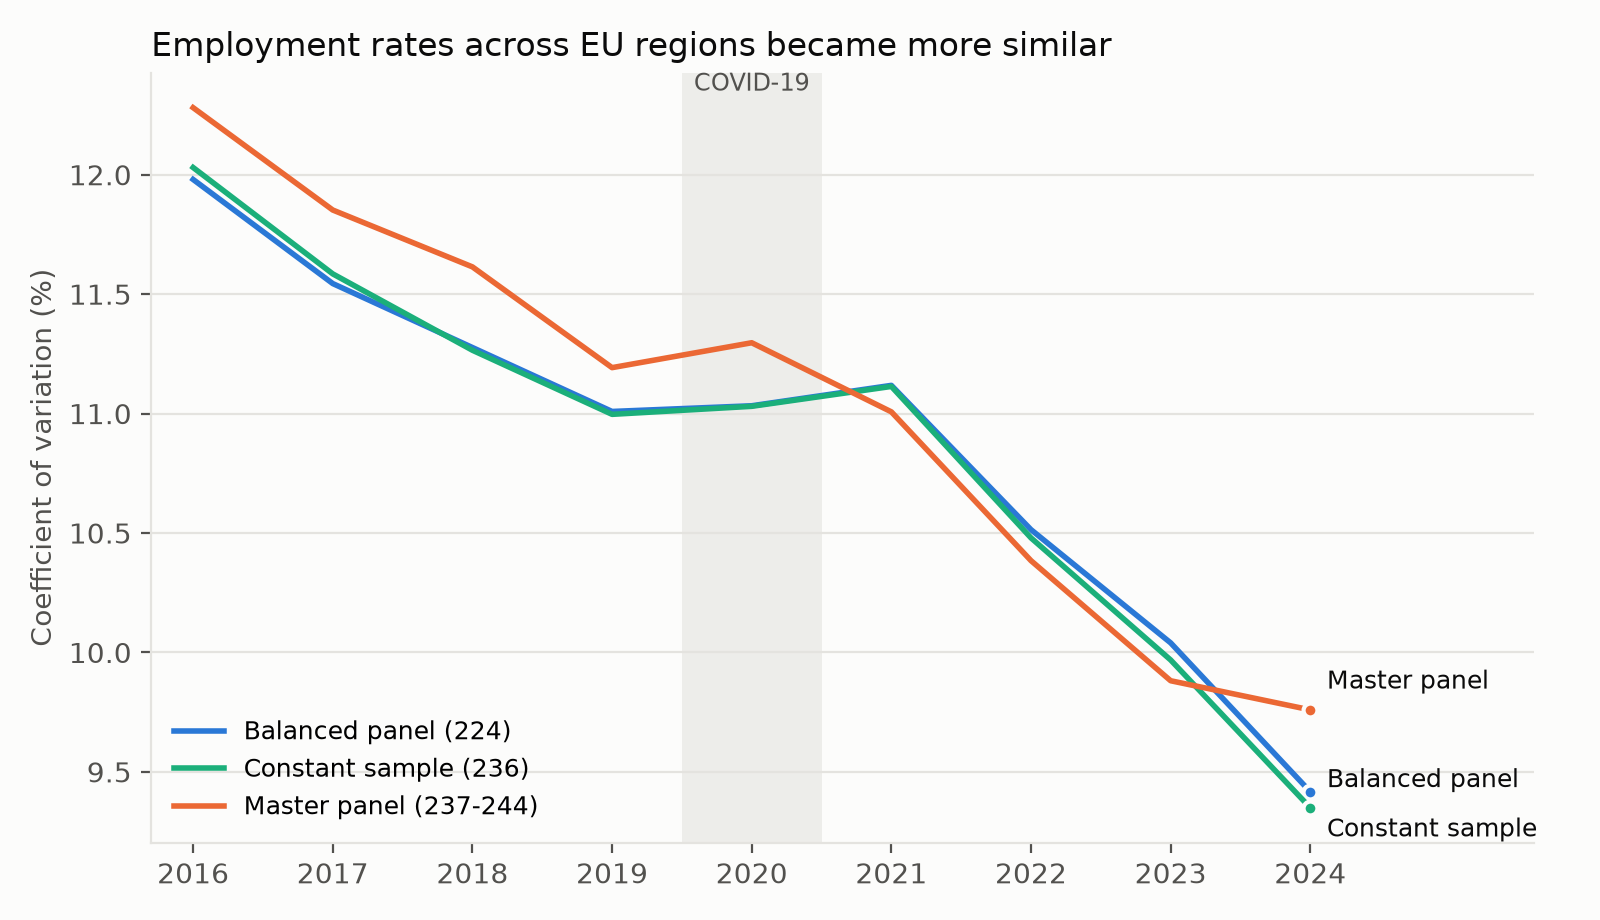

In [5]:
rq1b_out = OUTPUTS / "rq1b"
rq1b_fig = rq1b_out / "figures"
employment_dispersion = show_csv(
    rq1b_out / "rq1b_employment_dispersion_by_year.csv",
    ["sample", "year", "mean", "std_dev", "coef_variation_pct", "p10", "p90", "p90_minus_p10"],
    decimals=2,
)
show_image(rq1b_fig / "fig1_employment_cv_by_year.png")

### RQ1B interpretation

Employment gaps narrowed clearly. In the balanced sample, the mean employment rate increased from about **69.6% to 75.6%**, while the standard deviation fell from about **8.34 to 7.12 percentage points**. The coefficient of variation declined by roughly one fifth. This means weaker regions improved relative to stronger regions, although important gaps remain.

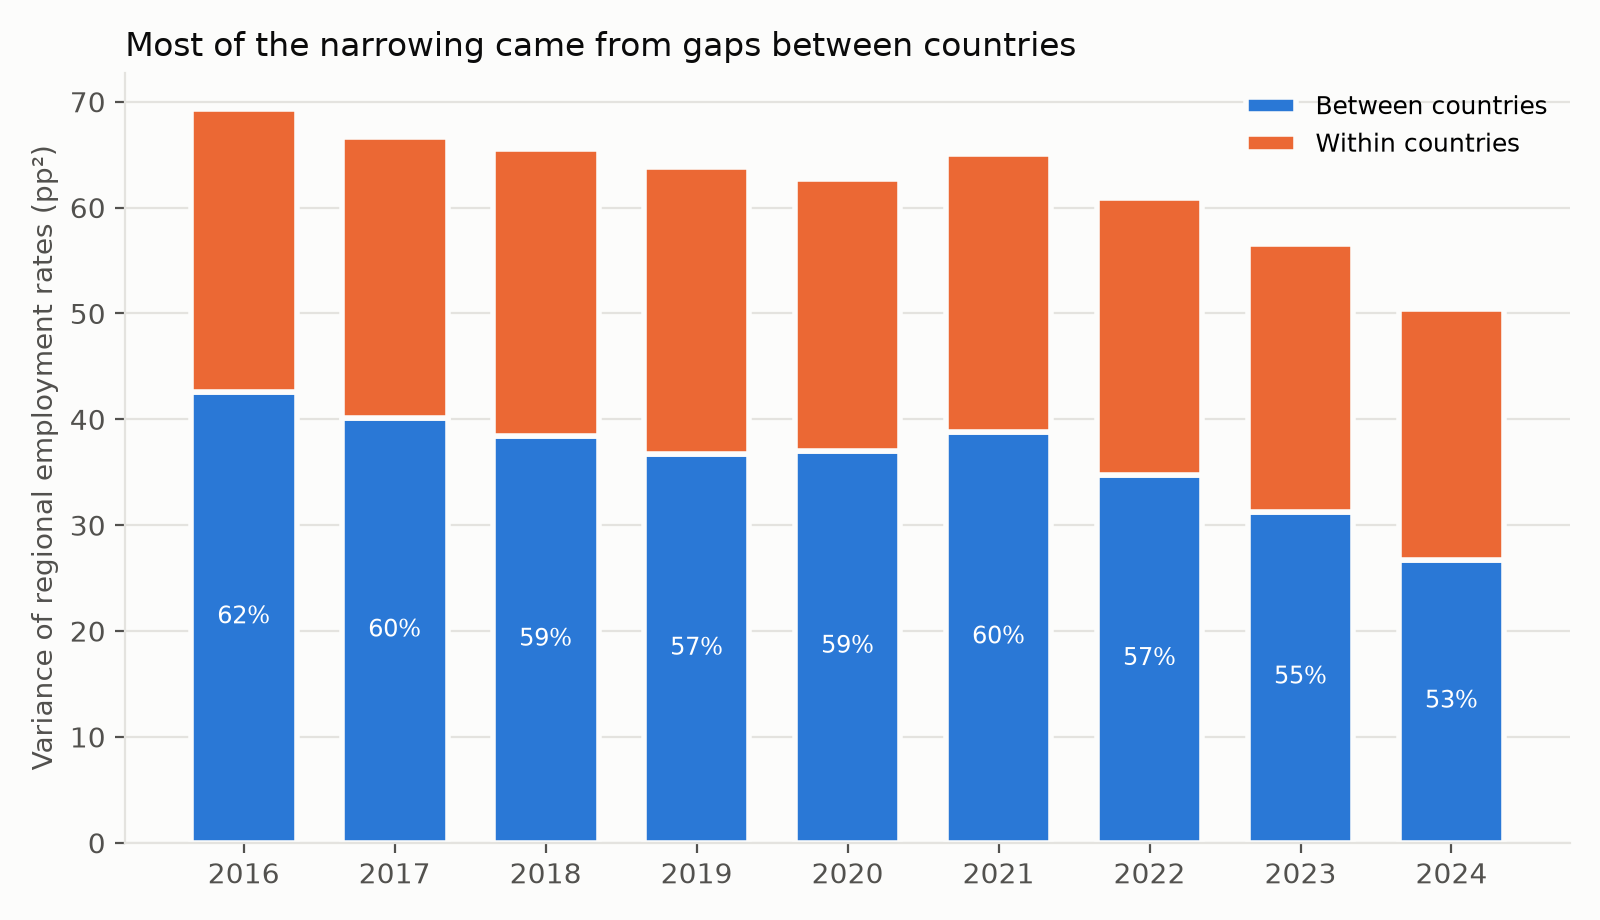

,year,total_variance,between_country_variance,within_country_variance,between_country_share_pct,within_country_share_pct
0,2016,69.282,42.622,26.660,61.520,38.480
1,2017,66.627,40.114,26.513,60.207,39.793
2,2018,65.531,38.381,27.150,58.569,41.431
3,2019,63.812,36.684,27.128,57.487,42.513
4,2020,62.683,37.049,25.634,59.105,40.895
5,2021,65.070,38.815,26.256,59.650,40.350
6,2022,60.865,34.739,26.126,57.076,42.924
7,2023,56.522,31.233,25.289,55.258,44.742
8,2024,50.449,26.679,23.770,52.883,47.117


,year,total_variance,between_country_variance,within_country_variance,between_country_share_pct,within_country_share_pct
0,2016,69.282,42.622,26.660,61.520,38.480
1,2017,66.627,40.114,26.513,60.207,39.793
2,2018,65.531,38.381,27.150,58.569,41.431
3,2019,63.812,36.684,27.128,57.487,42.513
4,2020,62.683,37.049,25.634,59.105,40.895
5,2021,65.070,38.815,26.256,59.650,40.350
6,2022,60.865,34.739,26.126,57.076,42.924
7,2023,56.522,31.233,25.289,55.258,44.742
8,2024,50.449,26.679,23.770,52.883,47.117


In [6]:
show_image(rq1b_fig / "fig3_between_within_country_variance.png")
show_csv(rq1b_out / "rq1b_between_within_country.csv", decimals=3)

The between-country and within-country decomposition helps locate the convergence. The group results indicate that much of the employment convergence came from lower-employment countries catching up, while differences among regions inside the same countries changed less.

# Part B. Beta convergence
Beta convergence tests whether regions with lower starting GDP grew faster than regions with higher starting GDP.

## 4. RQ2: Do poorer EU regions grow faster?

The preferred model regresses annualised log GDP growth from 2016 to 2024 on log GDP in 2016. Standard errors are clustered by country because regions within the same country may experience common shocks.

,model,n_regions,slope,se_cluster,p_value,r_squared,speed,half_life_yrs
0,A. Full sample,244,-0.0167,0.0045,0.0002,0.2371,0.0179,38.7851
1,B. Excl. commuter ring,237,-0.0168,0.0045,0.0002,0.2412,0.0180,38.4473
2,B2. Excl. core + ring,230,-0.0191,0.0043,0.0000,0.3002,0.0207,33.4276
3,C. Excl. break-flag regions,223,-0.0152,0.0051,0.0028,0.1937,0.0162,42.7837
4,D. Excl. influential regions,228,-0.0182,0.0032,0.0000,0.3691,0.0196,35.3119
5,E. End year 2023,244,-0.0167,0.0047,0.0004,0.2206,0.0177,39.1028
6,F. Excl. Ireland,241,-0.0183,0.0042,0.0000,0.2888,0.0198,34.9830
7,G. Excl. French overseas,239,-0.0176,0.0046,0.0001,0.2615,0.0189,36.5790
8,H. Excl. Ireland + overseas,236,-0.0193,0.0042,0.0000,0.3181,0.0210,32.9995
9,I. Excl. team outlier list,240,-0.0187,0.0043,0.0000,0.2820,0.0202,34.2836


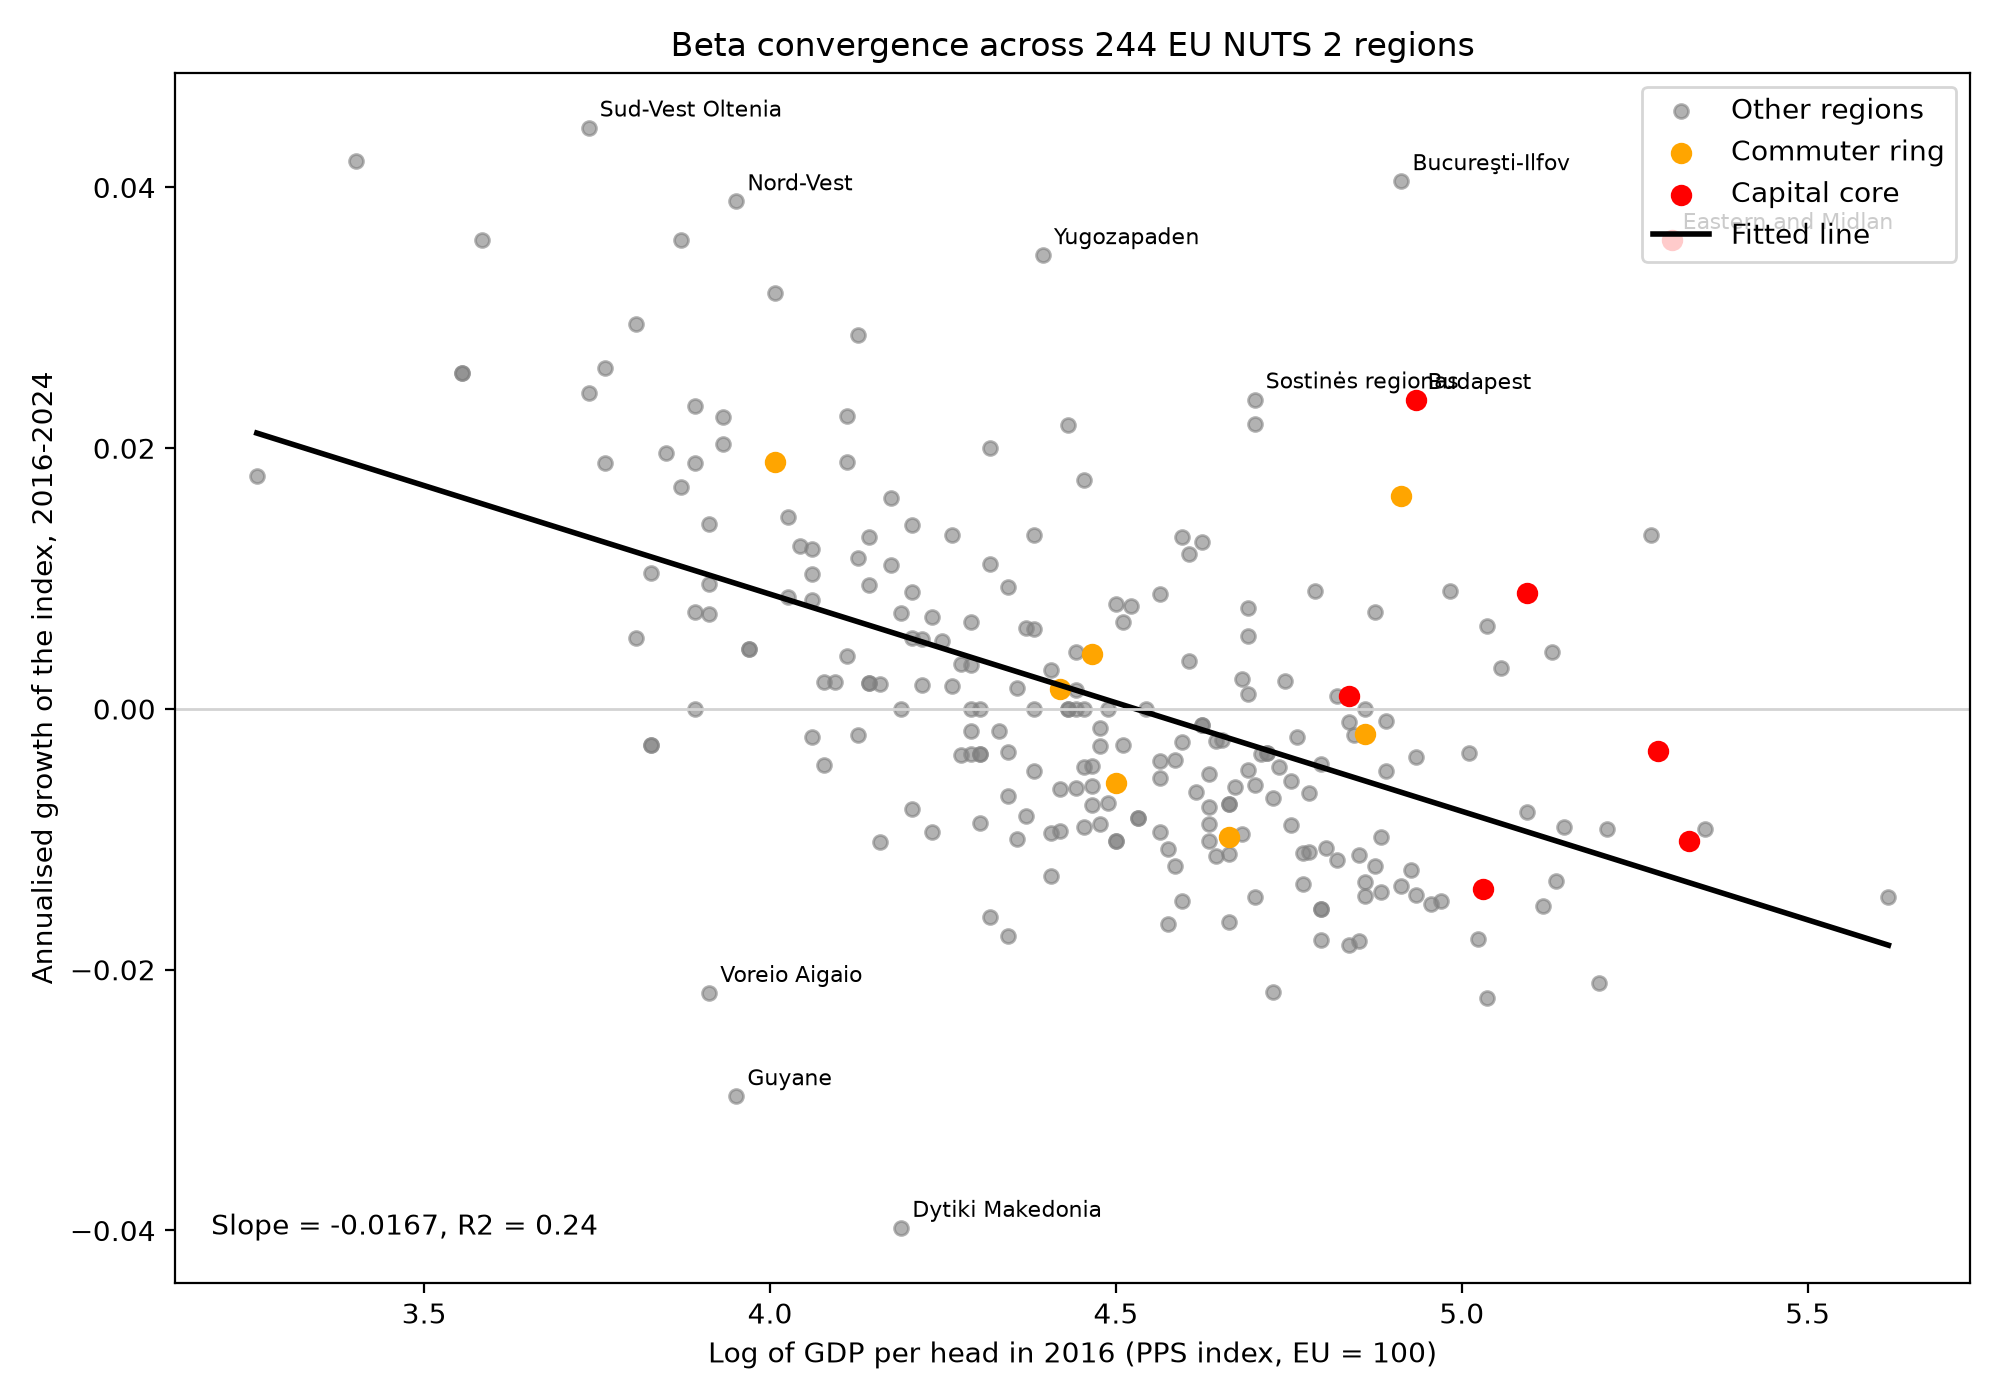

In [7]:
rq2_out = OUTPUTS
rq2_results = show_csv(rq2_out / "rq2_results.csv", decimals=4)
show_image(rq2_out / "rq2_plot1_scatter.png")

### RQ2 interpretation

The preferred estimate is approximately **−0.0167**, with a clustered standard error of about **0.0045** and **p = 0.0002**. The negative coefficient supports absolute beta convergence: poorer regions generally grew faster. The implied convergence speed is approximately **1.79% per year**, with a half-life close to **39 years**. The result is statistically strong but economically slow, and starting GDP explains only about **24%** of growth differences.

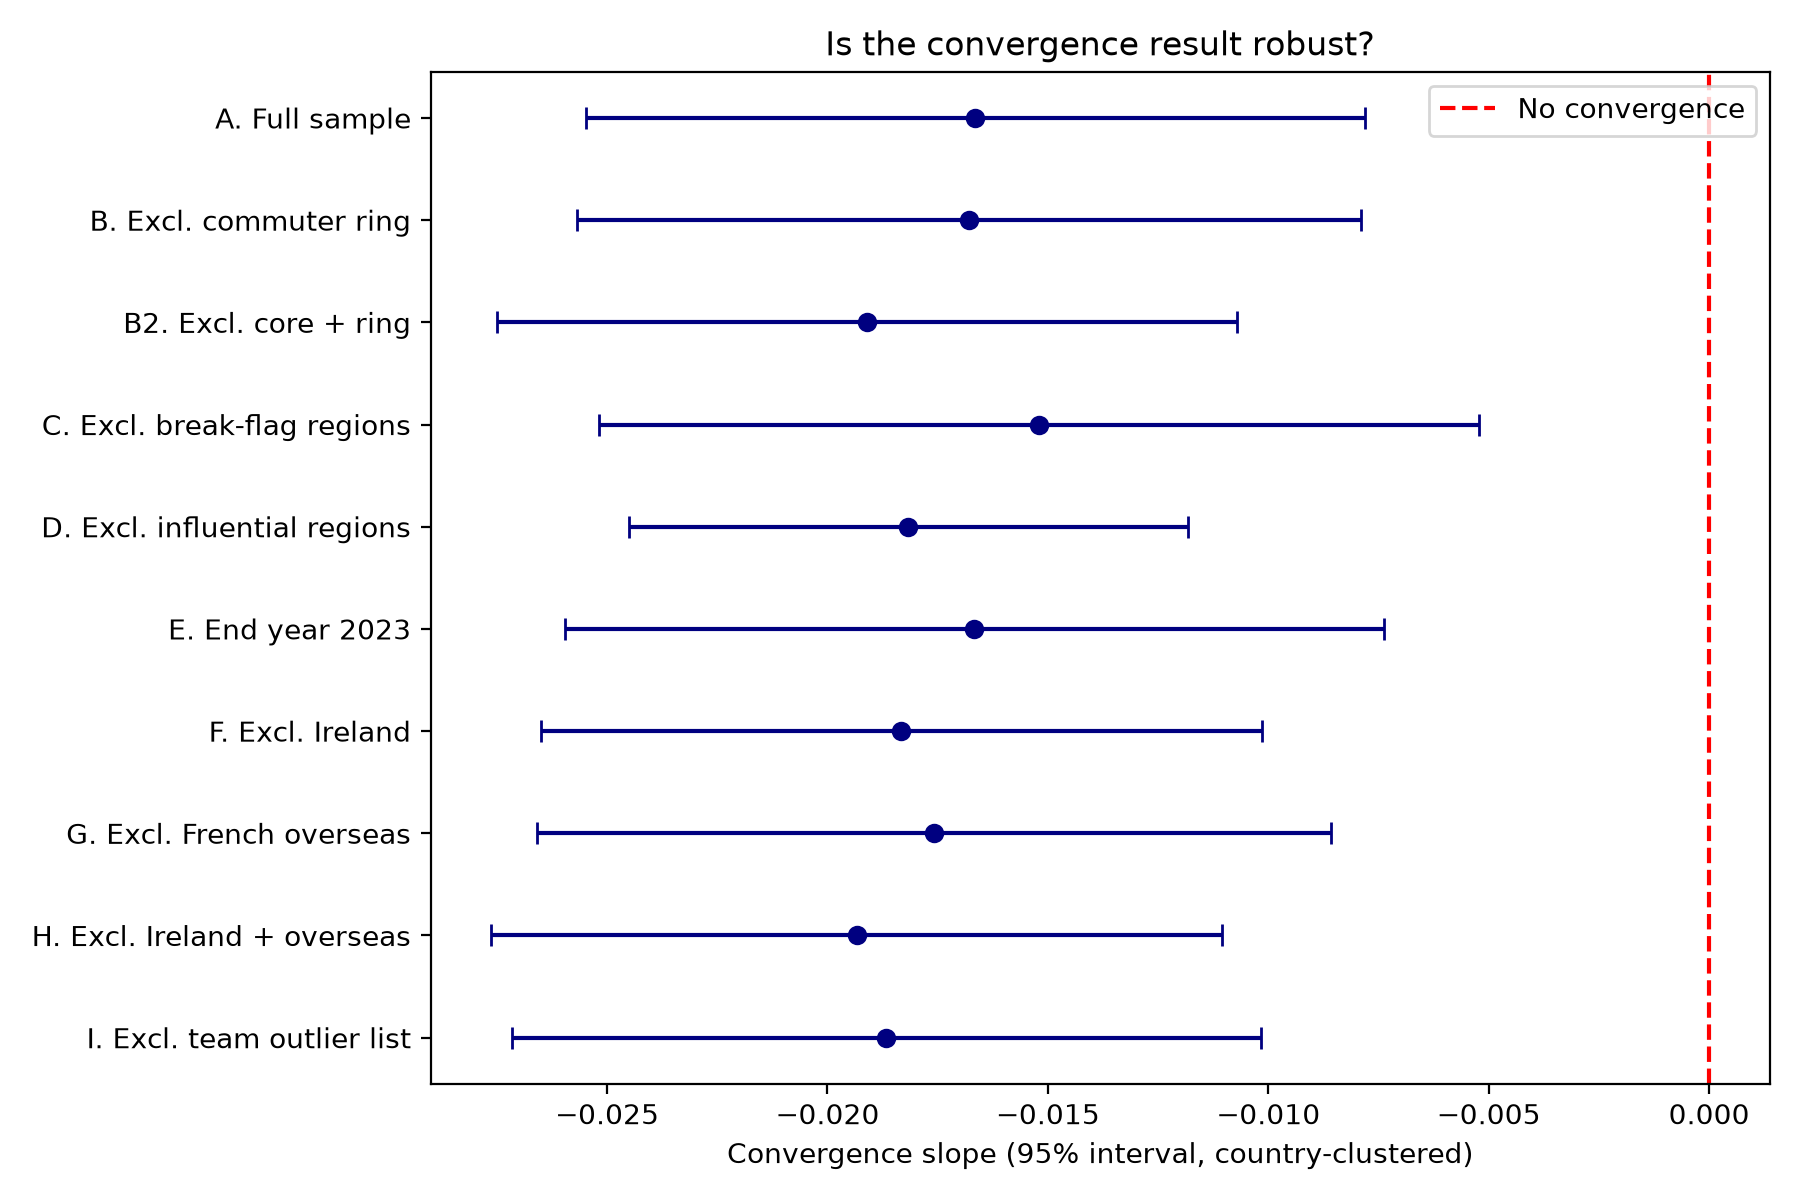

In [8]:
show_image(rq2_out / "rq2_plot2_robustness.png")

The robustness plot is retained because it communicates more than a single regression. The convergence coefficient remains negative after excluding commuter regions, capital cores, influential observations, Ireland, French overseas regions, and selected team outliers.

# Part C. Regional profiles and clustering

## 5. RQ3: Which regions behave alike?

RQ3 groups EU NUTS 2 regions according to similar GDP and labour-market behaviour. The regional profile uses six indicators calculated over the available period:

- average log GDP level;
- annual change in relative GDP position;
- average employment rate;
- change in employment rate;
- average unemployment rate; and
- change in unemployment rate.

All six variables are standardised before clustering so that variables measured on larger numerical scales do not dominate the distance calculation.

### 5.1 Method

The analysis applies **K-means clustering** with 50 initialisations and a fixed random seed of 42. Solutions from 2 to 8 clusters are compared using inertia for the elbow method and the silhouette score. The selected three-cluster solution is then checked against Ward hierarchical clustering and repeated 80% subsamples.

Principal component analysis is used only to display the six-dimensional standardised profiles in two dimensions. PC1 represents 53% and PC2 represents 23% of the variation, so the figure shows 76% of the total variation in the regional profiles.

In [2]:
from pathlib import Path
from runpy import run_path

# The notebook is inside the notebooks folder
ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

SRC = ROOT / "src"
OUTPUTS = ROOT / "outputs"

rq3_script = SRC / "rq3_clusters.py"
rq3_out = OUTPUTS / "rq3"

print("Project root:", ROOT)
print("RQ3 script:", rq3_script)
print("Script exists:", rq3_script.exists())

if rq3_script.exists():
    try:
        run_path(str(rq3_script), run_name="__main__")
        print("RQ3 analysis completed.")
    except Exception as exc:
        print(f"RQ3 analysis failed: {type(exc).__name__}: {exc}")
else:
    print(f"RQ3 script not found: {rq3_script}")

Project root: /Users/felix/EU_Regional_Convergence_Project
RQ3 script: /Users/felix/EU_Regional_Convergence_Project/src/rq3_clusters.py
Script exists: True
 k  inertia  silhouette
 2  874.413       0.369
 3  632.803       0.351
 4  538.279       0.260
 5  474.585       0.264
 6  421.492       0.273
 7  381.396       0.283
 8  347.296       0.250

Using k = 3
k-means vs Ward (ARI): 0.88
stability over 100 random 80% subsamples (mean ARI): 0.95

          gdp_level_log  gdp_rel_growth  emp_level  emp_change  unemp_level  unemp_change  n_regions  gdp_level_(index)
cluster                                                                                                               
1                 4.68           -0.49      76.45        4.19         5.72         -1.81        131             107.45
2                 4.20            1.90      72.91        8.28         5.43         -3.17         55              66.75
3                 4.14           -0.21      59.80        8.72        16.51 

### 5.2 Choosing the number of clusters

The elbow curve drops sharply from two to three clusters and then declines more gradually. The silhouette score is highest for two clusters at about 0.37 and remains relatively strong for three clusters at about 0.35. The member selected **three clusters** because the solution preserves good separation while providing a more informative distinction among regional profiles than a two-cluster split.

,k,inertia,silhouette
0,2,874.413,0.369
1,3,632.803,0.351
2,4,538.279,0.260
3,5,474.585,0.264
4,6,421.492,0.273
5,7,381.396,0.283
6,8,347.296,0.250


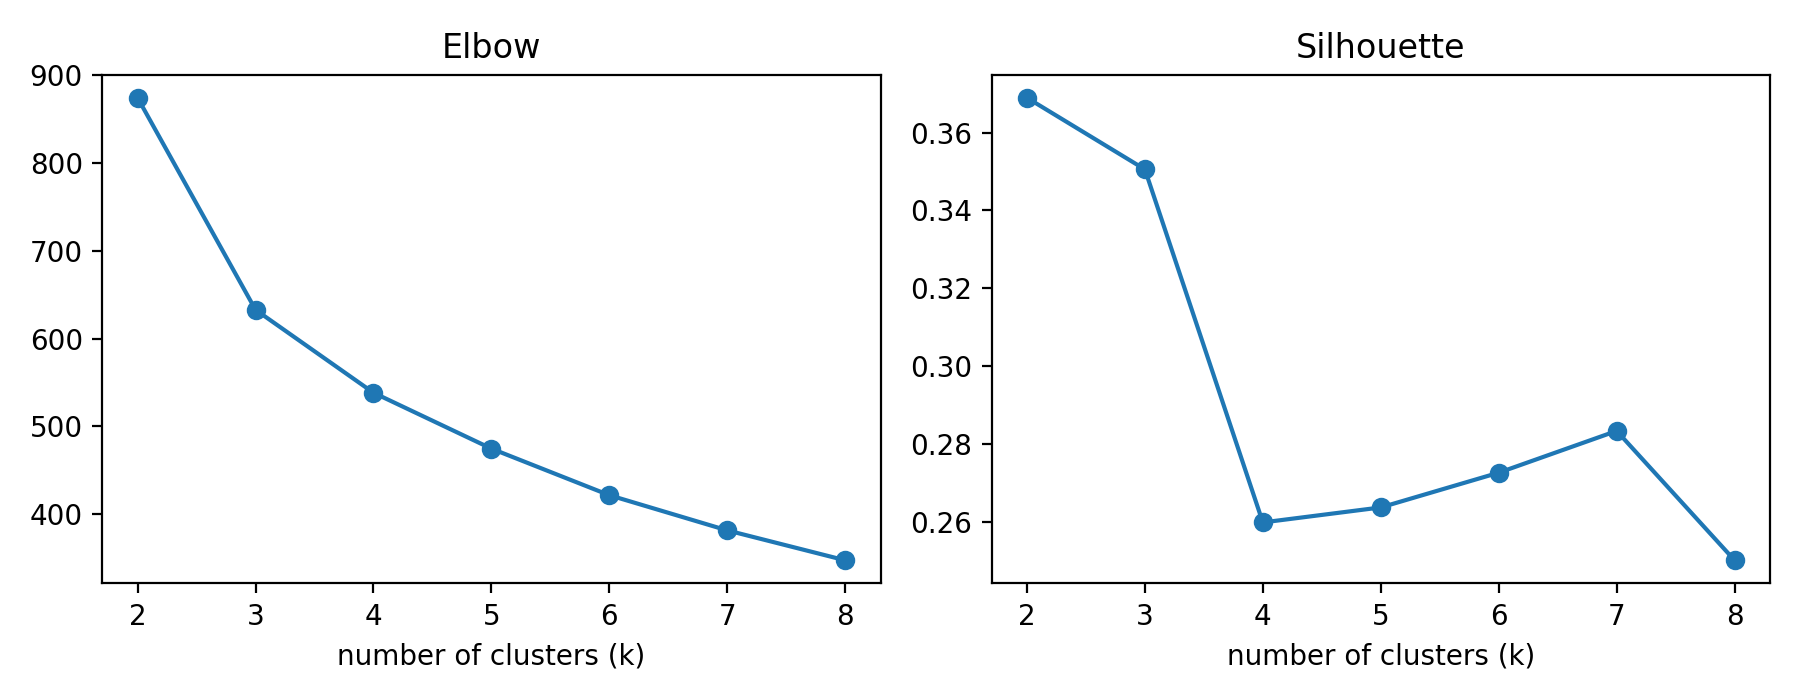

In [7]:
import pandas as pd
from IPython.display import display, Image

choose_k_path = rq3_out / "rq3_choose_k.csv"

if choose_k_path.exists():
    display(pd.read_csv(choose_k_path).round(3))
else:
    print(f"Table not found: {choose_k_path}. Run the RQ3 pipeline first.")

figure_path = rq3_out / "rq3_fig1_choose_k.png"
if figure_path.exists():
    display(Image(filename=str(figure_path), width=1000))
else:
    print(f"Visual not found: {figure_path}. Run the RQ3 pipeline first.")

### 5.3 Regional clusters in the PCA space

The PCA visual shows three recognisable groups. Cluster 3 is concentrated on the negative side of PC1 and is the most clearly separated group. Cluster 2 generally occupies the upper part of the figure, with higher PC2 values. Cluster 1 is the largest group and is concentrated mainly on the positive side of PC1, although some overlap remains near the centre.

The visible separation supports meaningful differences in economic performance profiles, but the overlap shows that regional economies do not form perfectly isolated categories.

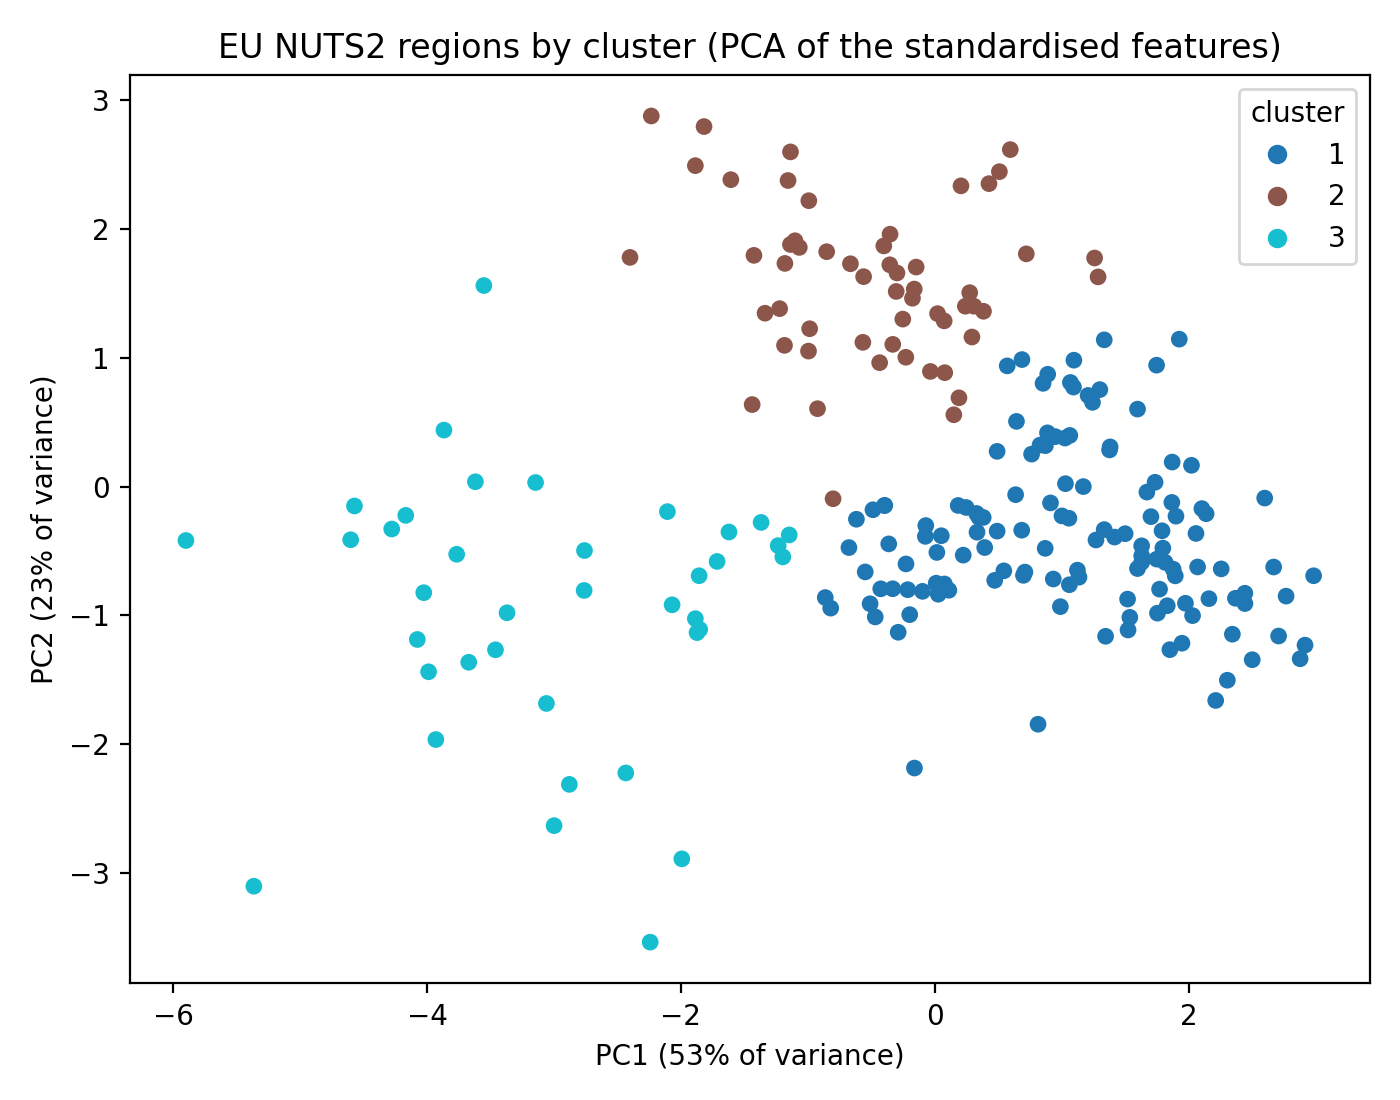

In [9]:
from IPython.display import display, Image

pca_figure = rq3_out / "rq3_fig2_clusters_pca.png"
if pca_figure.exists():
    display(Image(filename=str(pca_figure), width=900))
else:
    print(f"Visual not found: {pca_figure}. Run the RQ3 pipeline first.")

### 5.4 Cluster profiles and geographical interpretation

The cluster numbers are ordered from the highest average GDP level to the lowest. The profile table should therefore be used to describe the groups in real units rather than interpreting cluster numbers by themselves.

In [12]:
profiles_path = rq3_out / "rq3_cluster_profiles.csv"
if profiles_path.exists():
    profiles = pd.read_csv(profiles_path, index_col=0)
    display(profiles.round(2))
else:
    print(f"Table not found: {profiles_path}. Run the RQ3 pipeline first.")

country_clusters_path = rq3_out / "rq3_cluster_by_country.csv"
if country_clusters_path.exists():
    country_clusters = pd.read_csv(country_clusters_path, index_col=0)
    display(country_clusters.round(0))
else:
    print(f"Table not found: {country_clusters_path}. Run the RQ3 pipeline first.")

eta_squared_path = rq3_out / "rq3_country_eta_squared.csv"
if eta_squared_path.exists():
    display(pd.read_csv(eta_squared_path, index_col=0).round(2))
else:
    print(f"Table not found: {eta_squared_path}. Run the RQ3 pipeline first.")

,gdp_level_log,gdp_rel_growth,emp_level,emp_change,unemp_level,unemp_change,n_regions,gdp_level_(index)
cluster,,,,,,,,
1,4.68,-0.49,76.45,4.19,5.72,-1.81,131,107.45
2,4.20,1.90,72.91,8.28,5.43,-3.17,55,66.75
3,4.14,-0.21,59.80,8.72,16.51,-9.18,38,63.05


,1,2,3
country_code,,,
AT,9,0,0
BE,11,0,0
BG,0,6,0
CY,0,1,0
CZ,8,0,0
DE,28,0,0
DK,5,0,0
EE,1,0,0
EL,0,0,13


,share_explained_by_country
gdp_level_log,0.51
gdp_rel_growth,0.77
emp_level,0.58
emp_change,0.69
unemp_level,0.67
unemp_change,0.72


### 5.5 RQ3 conclusion

The clustering suggests that EU NUTS 2 regions can be organised into three broad economic-performance profiles based on GDP, employment, and unemployment levels and changes. The PCA figure shows substantial separation, especially for Cluster 3, but also some overlap between Clusters 1 and 2.

Country membership is compared with cluster membership using the adjusted Rand index and normalised mutual information. The country cross-tabulation and eta-squared results are necessary for the final geography judgment. If countries contain regions in several clusters and the country-comparison scores are low, the groups reflect economic performance more strongly than national geography. If most regions from the same country remain together and country explains a large share of the standardised variables, geography has a stronger role.

Where `sector_shares.csv` is available, the script also compares the performance clusters with clusters based on agriculture, industry, and service employment shares. This provides the direct test of whether similar regional behaviour reflects industrial structure.

# Part D. Connecting sigma and beta convergence

## 6. RQ4: Where do the two tests agree or disagree?

Beta convergence and sigma convergence answer related but different questions. Poor regions can grow faster on average while new shocks temporarily increase the overall spread. For this reason, negative beta is necessary but not sufficient for a continuous decline in sigma dispersion.

,start,end,pct_change,trend_per_year,years_rising
sd_log,0.3949,0.3551,-10.0880,-0.0047,1
cv,0.3977,0.3796,-4.5658,-0.0015,3
p90_p10,2.7634,2.3281,-15.7540,-0.0559,1
sd_log_excl_outliers,0.3797,0.3355,-11.6597,-0.0054,1
cv_excl_outliers,0.3675,0.3387,-7.8222,-0.0034,1


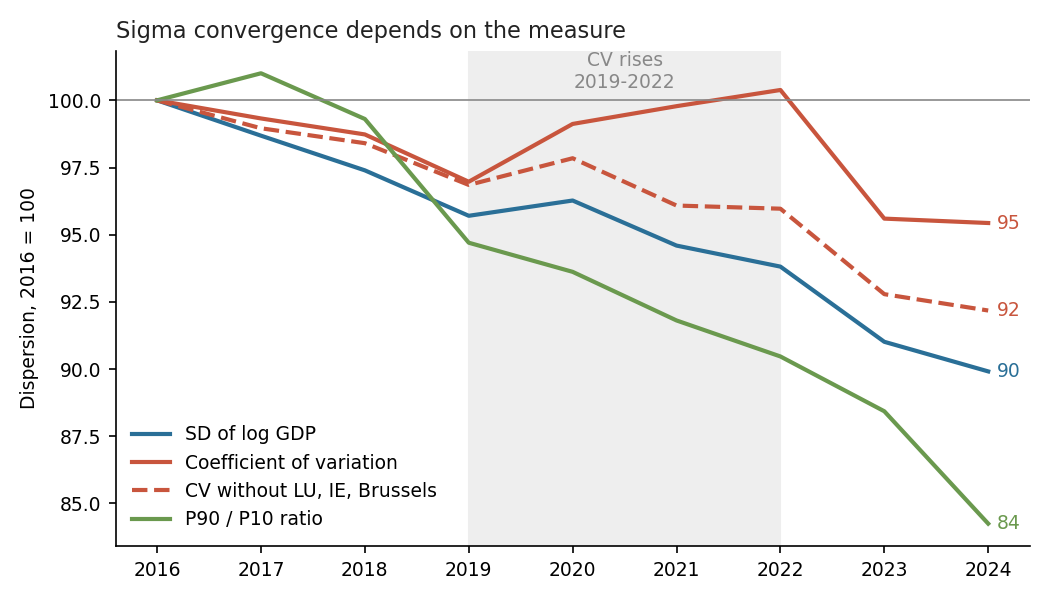

In [14]:
rq4_out = OUTPUTS / "rq4"

summary_path = rq4_out / "rq4_sigma_trend_summary.csv"
if summary_path.exists():
	display(pd.read_csv(summary_path, index_col=0).round(4))
else:
	print(f"Table not found: {summary_path}")

figure_path = rq4_out / "fig1_sigma_measures.png"
if figure_path.exists():
	display(Image(filename=str(figure_path)))
else:
	print(f"Visual not found: {figure_path}")

### Overall agreement

Across 2016 to 2024, the two approaches broadly agree. The GDP beta estimate is negative, while the standard deviation of log GDP falls by about **10.1%**, the coefficient of variation falls by about **4.6%**, and the P90 to P10 ratio falls by about **15.8%**. However, the measures do not move together in every individual year.

,period,beta,beta_significant_5pct,change_sd_log,change_cv,beta_says,sd_log_says,cv_says,agree_sd_log,agree_cv
0,2016-2017,-0.0151,True,-0.0052,-0.0027,converging,converging,converging,True,True
1,2017-2018,-0.0149,True,-0.0051,-0.0024,converging,converging,converging,True,True
2,2018-2019,-0.0192,True,-0.0067,-0.0070,converging,converging,converging,True,True
3,2019-2020,-0.0041,False,0.0022,0.0086,converging,diverging,diverging,False,False
4,2020-2021,-0.0223,True,-0.0066,0.0026,converging,converging,diverging,True,False
5,2021-2022,-0.0151,False,-0.0031,0.0024,converging,converging,diverging,True,False
6,2022-2023,-0.0350,True,-0.0111,-0.0190,converging,converging,converging,True,True
7,2023-2024,-0.0136,True,-0.0044,-0.0006,converging,converging,converging,True,True


,period,sample,var_start,var_end,change,catch_up_effect,shock_effect,check_sum
0,2016-2024,all,0.1553,0.1256,-0.0298,-0.0386,0.0089,-0.0298
1,2016-2024,excl. outliers,0.1436,0.1121,-0.0315,-0.0397,0.0082,-0.0315
2,2016-2017,all,0.1553,0.1513,-0.0041,-0.0047,0.0006,-0.0041
3,2017-2018,all,0.1513,0.1473,-0.0039,-0.0045,0.0005,-0.0039
4,2018-2019,all,0.1473,0.1423,-0.0051,-0.0056,0.0005,-0.0051
5,2019-2020,all,0.1423,0.1440,0.0017,-0.0012,0.0029,0.0017
6,2020-2021,all,0.1440,0.1390,-0.0050,-0.0064,0.0014,-0.0050
7,2021-2022,all,0.1390,0.1367,-0.0023,-0.0042,0.0019,-0.0023
8,2022-2023,all,0.1367,0.1287,-0.0080,-0.0094,0.0014,-0.0080
9,2023-2024,all,0.1287,0.1256,-0.0031,-0.0035,0.0004,-0.0031


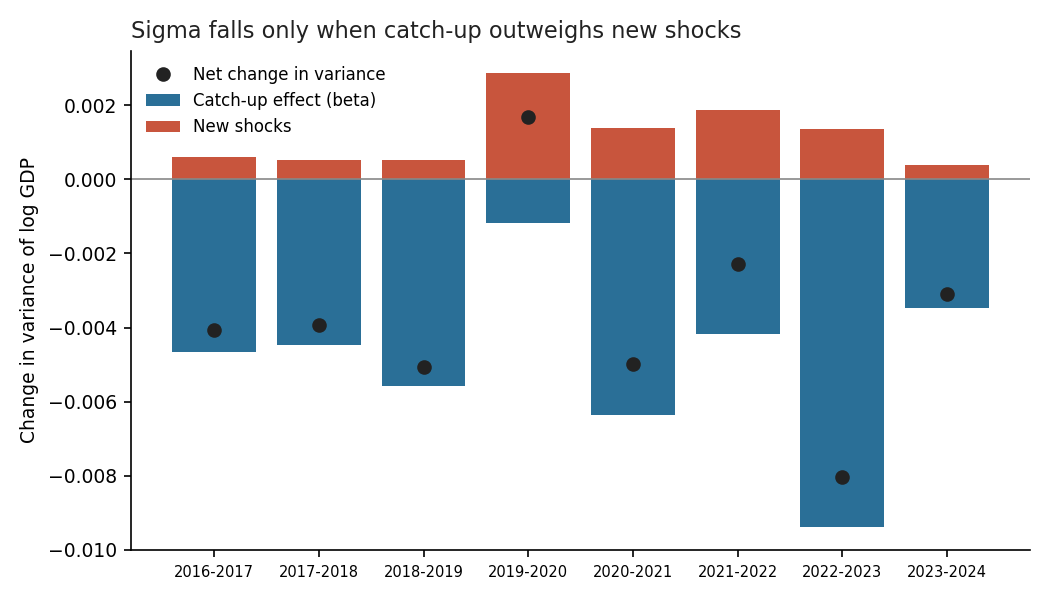

In [17]:
annual_agreement = pd.read_csv(rq4_out / "rq4_annual_agreement.csv")
display(annual_agreement.round(4))

variance_decomposition = pd.read_csv(rq4_out / "rq4_variance_decomposition.csv")
display(variance_decomposition.round(4))

figure = rq4_out / "fig3_variance_decomposition.png"
if figure.exists():
    display(Image(filename=str(figure), width=900))
else:
    print(f"Visual not found: {figure}")

### Timing of disagreement

The clearest disagreement occurs around **2019 to 2020**, when beta convergence was weak while sigma dispersion increased. In **2020 to 2021** and **2021 to 2022**, the coefficient of variation rose even though the standard deviation of log GDP fell. These periods show that conclusions can depend on the chosen dispersion measure and on temporary shocks.

## 7. Where is convergence happening?

The between-country and within-country split is important for policy. EU-wide convergence does not necessarily mean that every country is becoming internally more equal.

,total,between_countries,within_countries,share_within
year,,,,
2016,0.1553,0.0861,0.0692,0.4454
2017,0.1513,0.0830,0.0682,0.4510
2018,0.1473,0.0785,0.0689,0.4675
2019,0.1423,0.0727,0.0696,0.4892
2020,0.1440,0.0787,0.0652,0.4532
2021,0.1390,0.0738,0.0652,0.4689
2022,0.1367,0.0702,0.0665,0.4867
2023,0.1287,0.0623,0.0664,0.5160
2024,0.1256,0.0592,0.0664,0.5288


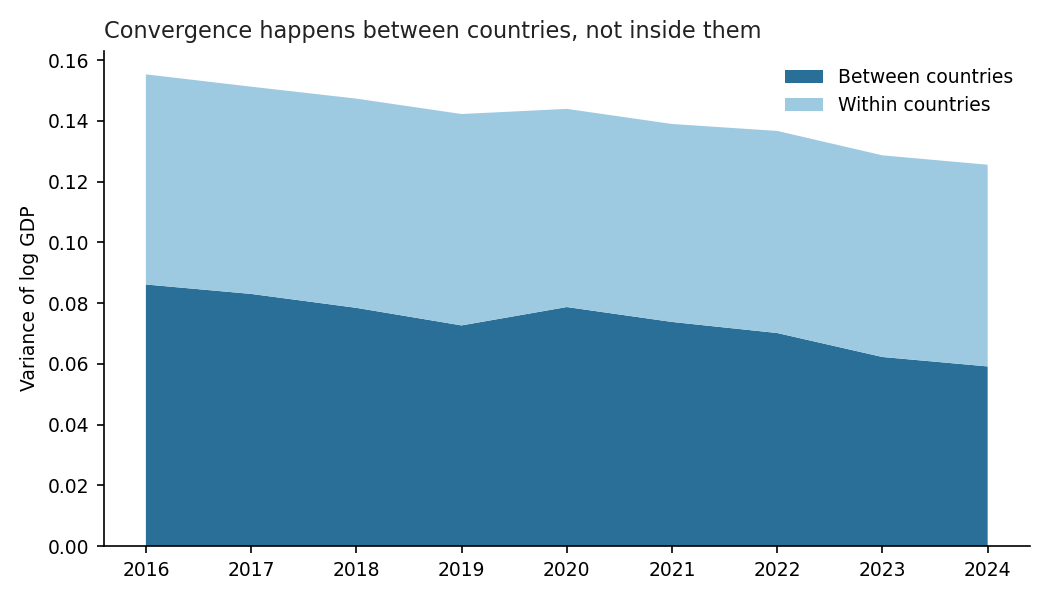

In [21]:
from IPython.display import Image, display
from pathlib import Path

between_within_path = rq4_out / "rq4_between_within.csv"
if between_within_path.exists():
    display(pd.read_csv(between_within_path, index_col=0).round(4))
else:
    print(f"Table not found: {between_within_path}")
figure_path = rq4_out / "fig4_between_within.png"
if figure_path.exists():
    display(Image(filename=str(figure_path), width=900))
else:
    print(f"Visual not found: {figure_path}")
# No additional display call is needed.

Between-country GDP inequality fell by about **31%**, while within-country inequality fell by only about **4%**. The within-country share of total regional inequality therefore increased from roughly **45% to 53%**. The convergence story is mainly one of countries catching up with one another, while internal regional disparities remain persistent.

## 8. Exceptions and regions left behind

In [ ]:
countries_path = rq4_out / "rq4_country_within_convergence.csv"
if countries_path.exists():
    countries = pd.read_csv(countries_path)
    display(countries.round(3))
else:
    print(f"Table not found: {countries_path}. Run the RQ4 pipeline first.")
regions_path = rq4_out / "rq4_region_exceptions.csv"
if regions_path.exists():
    regions = pd.read_csv(regions_path, index_col=0)
    exception_columns = [c for c in ["region_name", "country", "index_2016", "index_2024", "change_points", "pattern"] if c in regions.columns]
    if "pattern" in regions.columns:
        exception_rows = regions[regions["pattern"].astype(str).str.contains("exception", case=False, na=False)]
        display(exception_rows[exception_columns].sort_values("change_points").round(2))
    else:
        display(regions[exception_columns].round(2))
else:
    print("Regional exception table not found. Run the RQ4 pipeline first.")

NameError: name 'show_csv' is not defined

The project identifies countries where internal regional GDP gaps widened and regions that moved against the EU-wide pattern. These exceptions matter because an improving EU average can hide places that continue to fall behind. The group analysis identifies **17 initially poor regions that fell further behind** and **13 initially rich regions that pulled further ahead**.

# 9. Integrated conclusion

The four analyses give a consistent but qualified answer:

- **GDP sigma convergence:** Regional GDP dispersion declined overall, but not smoothly every year.
- **Employment sigma convergence:** Employment gaps narrowed clearly, and weaker regions generally improved.
- **GDP beta convergence:** Poorer regions grew faster on average, but the estimated speed of convergence is slow.
- **Regional profiles:** Standardised GDP, employment, and unemployment indicators produce three broad regional performance clusters. The PCA view captures 76% of the variation and shows clear separation for one group, with some overlap among the other regions. Country and sector comparisons determine how much of the grouping reflects geography and industrial structure.
- **Sigma versus beta:** The tests agree over the full period but can disagree temporarily when shocks increase dispersion.
- **Geographical pattern:** Convergence is stronger between countries than within countries.
- **Policy implication:** EU cohesion improved overall, but persistent within-country inequality and the regions moving against the general pattern remain important.

The safest final conclusion is that **EU NUTS 2 regions show real but slow convergence between 2016 and 2024. Convergence is uneven, sensitive to temporary shocks, and incomplete within individual countries.**

## 10. Main limitations

1. The study covers only nine years and includes the COVID-19 shock.
2. GDP in some regions is influenced by multinational profit booking, commuting, and provisional Eurostat observations.
3. Each region is weighted equally, regardless of population size.
4. Absolute beta convergence does not control for structural differences such as investment, education, sector composition, or institutions.
5. NUTS boundary changes and missing observations can affect balanced-panel comparisons.
6. The results describe convergence in GDP and employment, not household income or living standards directly.